#  쇼핑몰 리뷰 감성 분석  #
## Full Fine-Tuning vs PEFT 비교 ##



## 미션 개요 ##

쇼핑몰 리뷰 데이터를 대상으로 감성 분석 모델을 학습하고,  
**Full Fine-Tuning**과 **PEFT (LoRA)** 두 가지 학습 방식을 비교 분석합니다.

---

### 사용 데이터셋 ###

- **출처:** AI Hub 속성기반 감정분석 데이터
- **도메인:** 쇼핑몰 패션 리뷰
- **형식:** JSON  
  - `RawText`
  - `GeneralPolarity`

#### 라벨 구성 ####

| GeneralPolarity | 의미 | 변환 라벨 |
|---|---|---|
| -1 | 부정 (Negative) | 0 |
| 0 | 중립 (Neutral) | 1 |
| 1 | 긍정 (Positive) | 2 |

---

### 전체 파이프라인 ###

1. 데이터 로드 및 분할  
   - Train / Validation / Test = `70 / 15 / 15`
2. 데이터 전처리  
   - KcELECTRA 공식 `clean` 함수 적용
   - 길이 필터 적용
3. Full Fine-Tuning 학습
4. PEFT (LoRA) 학습
5. 최종 평가  
   - Test set 기반 평가
6. 두 방식 비교 분석

> ⚠️ **Test set은 최종 평가 단계에서만 사용합니다.**  
> 모든 중간 실험의 성능 판단은 **Validation set 기준**으로만 진행합니다.

---

### 최종 적용 조건 요약 ###

#### 데이터 전처리 ####

| 항목 | 내용 |
|---|---|
| 결측치 / 중복 제거 | 로드 시 자동 처리 |
| 라벨 변환 | `-1 → 0`, `0 → 1`, `1 → 2` |
| 텍스트 정제 | KcELECTRA 공식 `clean` 함수 |
| 길이 필터 | 10자 미만 텍스트 제거 |
| 최대 토큰 길이 | 128 |

#### Full Fine-Tuning #### 

| 항목 | 값 |
|---|---|
| 모델 | `beomi/KcELECTRA-base` |
| Epoch | 3 |
| Batch Size | 16 |
| Learning Rate | `2e-5` |
| Warmup Ratio | 0.1 |
| Weight Decay | 0.01 |
| LR Scheduler | cosine |

#### PEFT (LoRA) #####

| 항목 | 값 |
|---|---|
| 모델 | `beomi/KcELECTRA-base` |
| `r` | 32 |
| `lora_alpha` | 64 |
| `lora_dropout` | 0.05 |
| `target_modules` | `query`, `key`, `value`, `output.dense` |
| Learning Rate | `1e-4` |
| Epoch | 3 |
| Batch Size | 16 |

---

### 평가 지표 ###

| 지표 | 설명 |
|---|---|
| **Macro F1** | 주요 평가 지표. 클래스 불균형과 관계없이 각 클래스 F1의 평균을 반영 |
| Accuracy | 전체 예측 정확도 |
| Per-class F1 | 클래스별 성능 진단 |
| Confusion Matrix | 오분류 패턴 시각화 |
| 모델 파일 크기 | 배포 효율성 비교 |
| 학습 파라미터 수 | 두 방식의 구조적 차이 비교 |

---

### 실험 목적 ###

본 실험의 목적은 동일한 데이터셋과 동일한 백본 모델(`KcELECTRA-base`)을 기준으로,  
**모든 파라미터를 업데이트하는 Full Fine-Tuning 방식**과  
**일부 적응 파라미터만 학습하는 PEFT (LoRA) 방식**을 비교하는 데 있습니다.

이를 통해 다음 항목을 함께 분석합니다.

- 성능 차이
- 학습 효율성 차이
- 저장 용량 차이
- 실제 활용 및 배포 관점에서의 장단점

## 1. 환경 설정 ##

라이브러리 설치 및 임포트, 시드 고정, 실행 환경(Colab/로컬) 경로를 설정합니다.

In [ ]:
# # 1-a | Colab 환경 연결
# from google.colab import drive
# drive.mount("/content/drive", force_remount=True)

# DATA_DIR = "/content/drive/MyDrive/data/review-sentiment-analysis/쇼핑몰/01. 패션"
# LOG_DIR  = "/content/drive/MyDrive/data/experiment_logs"

# ----------------------------------

# 1-b | 로컬 환경 연결

DATA_DIR = r"D:\code_it\mission\mission13\review-sentiment-analysis\쇼핑몰\01. 패션"
LOG_DIR  = r"D:\code_it\mission\mission13\experiment_logs"

In [2]:
# 필요한 라이브러리 설치

!pip install -q datasets accelerate evaluate
!pip install -q peft
!pip install -q transformers peft datasets evaluate accelerate scikit-learn
!pip install -q soynlp emoji

ERROR: Invalid requirement: '#'

[notice] A new release of pip is available: 24.0 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# 셀 2 | 라이브러리 임포트 & 시드 고정
import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import torch
import platform
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
Path(LOG_DIR).mkdir(parents=True, exist_ok=True)

# 시드 고정
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# ── 한글 폰트 설정 ────────────────────────────────────────────────────────
system_name = platform.system()

if 'COLAB_GPU' in os.environ or 'COLAB_RELEASE_TAG' in os.environ:
    import subprocess
    subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], capture_output=True)
    fm.fontManager.__init__()
    fm._load_fontmanager(try_read_cache=False)
    plt.rcParams['font.family'] = 'NanumGothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("코랩 한글 폰트 설정 완료 (NanumGothic)")

elif system_name == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("macOS 한글 폰트 설정 완료 (AppleGothic)")

elif system_name == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("Windows 한글 폰트 설정 완료 (Malgun Gothic)")

else:
    plt.rcParams['font.family'] = 'NanumGothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("Linux 한글 폰트 설정 완료 (NanumGothic)")

print(f"■ 현재 환경 : {system_name}")
print(f"■ 적용 폰트 : {plt.rcParams['font.family']}")

# 라벨 매핑
POLARITY_TO_LABEL = {-1: 0, 0: 1, 1: 2}
LABEL_TO_NAME     = {0: "negative", 1: "neutral", 2: "positive"}
NUM_LABELS        = 3

# 디바이스 확인
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"seed={SEED} | device={device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Windows 한글 폰트 설정 완료 (Malgun Gothic)
■ 현재 환경 : Windows
■ 적용 폰트 : ['Malgun Gothic']
seed=42 | device=cuda
GPU: NVIDIA GeForce RTX 3070 Ti


In [4]:
# 셀 3 | 데이터 로드
def load_json_files(data_dir: str) -> pd.DataFrame:
    json_paths = [
        os.path.join(root, file)
        for root, _, files in os.walk(data_dir)
        for file in files
        if file.endswith(".json")
    ]
    print(f"탐색된 JSON 파일 수: {len(json_paths)}개")

    records   = []
    skip_file = 0
    skip_item = 0

    for path in json_paths:
        try:
            with open(path, "r", encoding="utf-8") as f:
                items = json.load(f)
            if isinstance(items, dict):
                items = [items]

            for item in items:
                polarity = item.get("GeneralPolarity", None)
                text     = item.get("RawText", None)

                if text is None or polarity is None:
                    skip_item += 1
                    continue

                polarity = int(polarity)
                if polarity not in POLARITY_TO_LABEL:
                    skip_item += 1
                    continue

                text = str(text).strip()
                if not text:
                    skip_item += 1
                    continue

                records.append({
                    "text" : text,
                    "label": POLARITY_TO_LABEL[polarity],
                })

        except Exception as e:
            skip_file += 1
            print(f"파싱 실패: {os.path.basename(path)} — {e}")

    df = pd.DataFrame(records)
    before = len(df)
    df = df.drop_duplicates().dropna().reset_index(drop=True)
    after  = len(df)

    print(f"총 수집: {before:,} | 중복/결측 제거: {before-after:,} | 유효하지 않은 항목: {skip_item:,} | 파싱 실패 파일: {skip_file}")
    print(f"최종 데이터: {after:,}개")

    return df


df_raw = load_json_files(DATA_DIR)

# 라벨 분포 확인
label_counts = df_raw["label"].value_counts().sort_index()
for label_id, count in label_counts.items():
    print(f"  {label_id} ({LABEL_TO_NAME[label_id]:>8}): {count:>6,}개  ({count/len(df_raw)*100:.1f}%)")

탐색된 JSON 파일 수: 450개
총 수집: 44,398 | 중복/결측 제거: 1 | 유효하지 않은 항목: 598 | 파싱 실패 파일: 0
최종 데이터: 44,397개
  0 (negative):  9,264개  (20.9%)
  1 ( neutral):  8,683개  (19.6%)
  2 (positive): 26,450개  (59.6%)


## 2. 데이터 로드 및 분할 ##

JSON 파일에서 리뷰 텍스트(`RawText`)와 감성 라벨(`GeneralPolarity`)을 로드합니다.  
전체 데이터를 **train 70% / val 15% / test 15%** 로 분할하며,  
`stratify` 옵션으로 각 split의 클래스 비율을 동일하게 유지합니다.

In [5]:
# 셀 4 | 데이터 분할 (train 70 / val 15 / test 15)
from sklearn.model_selection import train_test_split

df_train, df_temp = train_test_split(
    df_raw,
    test_size=0.30,
    stratify=df_raw["label"],
    random_state=SEED,
)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    stratify=df_temp["label"],
    random_state=SEED,
)

# ⚠️ test set 격리 — 최종 평가(파이프라인 10번)에서만 사용
FINAL_TEST_SET = df_test.copy()
del df_test

df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)

print(f"train : {len(df_train):,}개  ({len(df_train)/len(df_raw)*100:.1f}%)")
print(f"val   : {len(df_val):,}개  ({len(df_val)/len(df_raw)*100:.1f}%)")
print(f"test  : {len(FINAL_TEST_SET):,}개  ({len(FINAL_TEST_SET)/len(df_raw)*100:.1f}%)")
print(f"total : {len(df_raw):,}개")

print("\n▶ split별 라벨 분포")
for split_name, split_df in [("train", df_train), ("val", df_val), ("test", FINAL_TEST_SET)]:
    dist = split_df["label"].value_counts(normalize=True).sort_index()
    dist_str = "  ".join([f"{LABEL_TO_NAME[i]}: {v*100:.1f}%" for i, v in dist.items()])
    print(f"  {split_name:5} | {dist_str}")

train : 31,077개  (70.0%)
val   : 6,660개  (15.0%)
test  : 6,660개  (15.0%)
total : 44,397개

▶ split별 라벨 분포
  train | negative: 20.9%  neutral: 19.6%  positive: 59.6%
  val   | negative: 20.9%  neutral: 19.6%  positive: 59.6%
  test  | negative: 20.9%  neutral: 19.5%  positive: 59.6%


## 3. 탐색적 데이터 분석 (EDA) ##

train set을 기준으로 클래스 분포, 텍스트 길이, 토큰 길이를 분석합니다.  
이 분석 결과는 이후 전처리 조건(길이 필터, max_length 설정)의 근거로 사용됩니다.

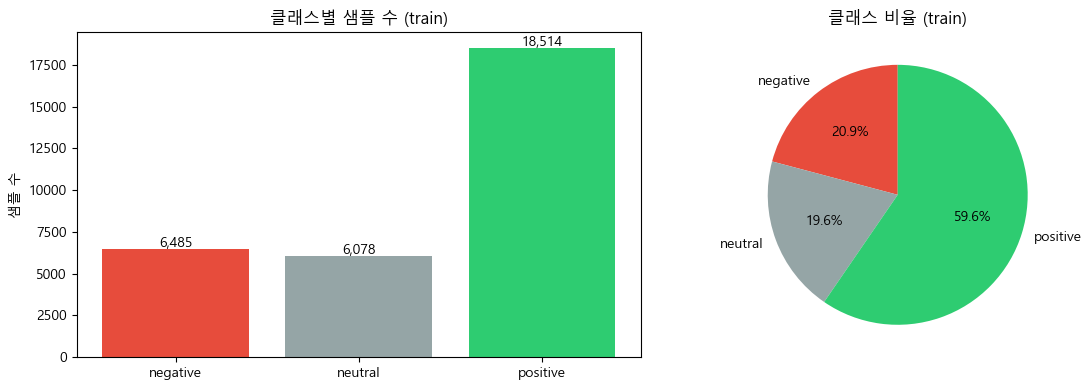


▶ 클래스별 샘플 수
  negative:  6,485개  (20.9%)
   neutral:  6,078개  (19.6%)
  positive: 18,514개  (59.6%)

  최대/최소 클래스 비율: 3.05배 차이


In [6]:
# 셀 5-a | 클래스 분포 시각화 (train 기준)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

label_counts = df_train["label"].value_counts().sort_index()
label_names  = [LABEL_TO_NAME[i] for i in label_counts.index]
colors       = ["#E74C3C", "#95A5A6", "#2ECC71"]

# 막대 그래프
axes[0].bar(label_names, label_counts.values, color=colors)
axes[0].set_title("클래스별 샘플 수 (train)")
axes[0].set_ylabel("샘플 수")
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 100, f"{v:,}", ha="center", fontsize=10)

# 파이 차트
axes[1].pie(
    label_counts.values,
    labels=label_names,
    autopct="%1.1f%%",
    colors=colors,
    startangle=90,
)
axes[1].set_title("클래스 비율 (train)")

plt.tight_layout()
plt.show()

print("\n▶ 클래스별 샘플 수")
for i, count in label_counts.items():
    print(f"  {LABEL_TO_NAME[i]:>8}: {count:>6,}개  ({count/len(df_train)*100:.1f}%)")
print(f"\n  최대/최소 클래스 비율: {label_counts.max()/label_counts.min():.2f}배 차이")

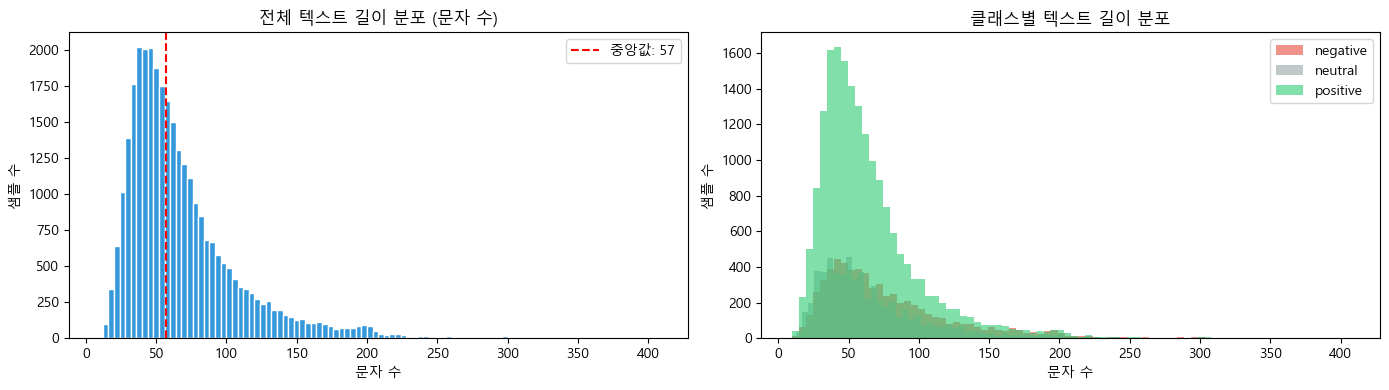

▶ 텍스트 길이 백분위수 (문자 수, train 기준)
    5%:    26자
   10%:    30자
   25%:    41자
   50%:    57자
   75%:    83자
   90%:   121자
   95%:   153자
   99%:   214자

  min: 8자  |  max: 408자


In [7]:
# 셀 5-b | 텍스트 길이 분포 (문자 수 기준, train 기준)
df_train["char_len"] = df_train["text"].str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 전체 길이 분포
axes[0].hist(df_train["char_len"], bins=100, color="#3498DB", edgecolor="white")
axes[0].set_title("전체 텍스트 길이 분포 (문자 수)")
axes[0].set_xlabel("문자 수")
axes[0].set_ylabel("샘플 수")
axes[0].axvline(df_train["char_len"].median(), color="red", linestyle="--", label=f"중앙값: {df_train['char_len'].median():.0f}")
axes[0].legend()

# 클래스별 길이 분포
for label_id, color in zip([0, 1, 2], colors):
    subset = df_train[df_train["label"] == label_id]["char_len"]
    axes[1].hist(subset, bins=80, alpha=0.6, label=LABEL_TO_NAME[label_id], color=color)
axes[1].set_title("클래스별 텍스트 길이 분포")
axes[1].set_xlabel("문자 수")
axes[1].set_ylabel("샘플 수")
axes[1].legend()

plt.tight_layout()
plt.show()

# 백분위수 출력
print("▶ 텍스트 길이 백분위수 (문자 수, train 기준)")
percentiles = [5, 10, 25, 50, 75, 90, 95, 99]
for p in percentiles:
    val = int(np.percentile(df_train["char_len"], p))
    print(f"  {p:>3}%: {val:>5,}자")
print(f"\n  min: {df_train['char_len'].min()}자  |  max: {df_train['char_len'].max():,}자")

In [8]:
# 셀 5-c | 짧은 텍스트 샘플 확인 (train 기준)
thresholds = [5, 10, 20, 30]

print("▶ 길이 threshold별 해당 샘플 수")
for t in thresholds:
    count = (df_train["char_len"] < t).sum()
    print(f"  {t:>2}자 미만: {count:>5,}개  ({count/len(df_train)*100:.2f}%)")

# 길이 기준 하위 샘플 직접 출력
SAMPLE_THRESHOLD = 20  # 육안 확인할 기준 (변경 가능)
short_samples = df_train[df_train["char_len"] < SAMPLE_THRESHOLD].sample(
    n=min(20, (df_train["char_len"] < SAMPLE_THRESHOLD).sum()),
    random_state=SEED
).reset_index(drop=True)

print(f"\n▶ {SAMPLE_THRESHOLD}자 미만 샘플 (최대 20개)")
for _, row in short_samples.iterrows():
    print(f"  [{LABEL_TO_NAME[row['label']]:>8}] ({row['char_len']:>2}자) {repr(row['text'])}")

▶ 길이 threshold별 해당 샘플 수
   5자 미만:     0개  (0.00%)
  10자 미만:     1개  (0.00%)
  20자 미만:   454개  (1.46%)
  30자 미만: 2,782개  (8.95%)

▶ 20자 미만 샘플 (최대 20개)
  [positive] (19자) '원단도부드럽고 홈웨어로편하고좋습니다'
  [negative] (18자) '허리사이즈가 크고 기장도 길어요ㅠ'
  [positive] (18자) '좋습니다.따뜻하고 세탁후변형없네요'
  [positive] (10자) '따뜻하고 품질좋네요'
  [positive] (17자) '정말 가볍지만 가격대비 만족해요'
  [ neutral] (17자) '입기 편한데 보플이 금방생기네요'
  [positive] (19자) '디자인 이뻐요.가격도작하고대박나세ㅛ'
  [positive] (18자) '가볍고 보온성 가격 모두 좋아요.'
  [ neutral] (17자) '두툼한건아니여도 가격대비 좋아요'
  [ neutral] (16자) '품은 맞는데 소매가 좀 기네요'
  [positive] (15자) '모양이깔끔해서 착용하니예뻐요'
  [positive] (17자) '가볍고 따뜻해요. 맵시도 좋아요'
  [positive] (14자) '크고양도많쿠좋아여  좋아요'
  [positive] (19자) '원단이 시원하고 가성비 디자인 굿!'
  [positive] (19자) '배송 굿 니트 착용감 좋고 가볍네요'
  [ neutral] (17자) '색감좋고 탄력좋은데 좀 두꺼워요'
  [positive] (19자) '디자인 컬러 예쁘고 제질도 괜찮네요'
  [positive] (15자) '도톰하니  따뜻해서  좋네요'
  [ neutral] (18자) '색상이 이쁘네요 하늘색은 비침요ㅠ'
  [positive] (15자) '가볍고따뜻해서편하게자주입어요'


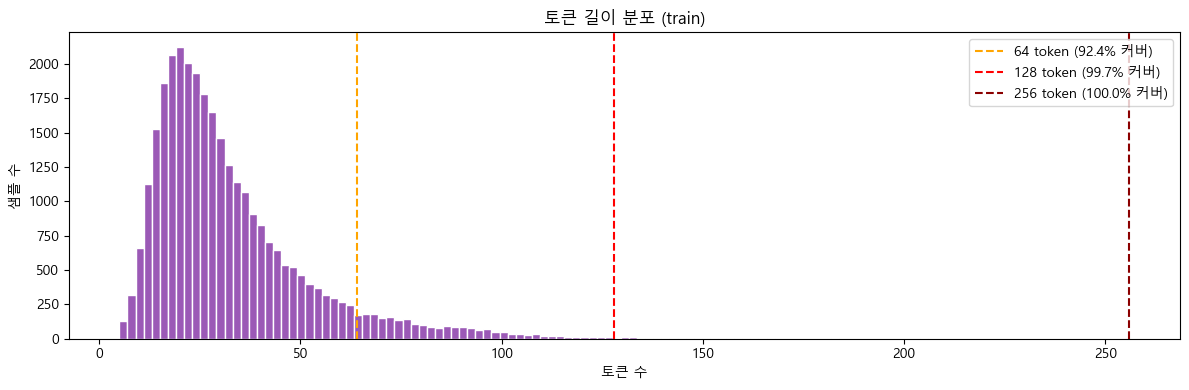

▶ 토큰 길이 백분위수 (train 기준)
   50%:   28 tokens
   75%:   40 tokens
   90%:   59 tokens
   95%:   74 tokens
   99%:  105 tokens

  min: 5  |  max: 206

▶ max_length별 커버리지
   64 tokens 이하: 92.37%
  128 tokens 이하: 99.67%
  256 tokens 이하: 100.00%


In [9]:
# 셀 5-d | 토큰 길이 분포 (train 기준)
from transformers import AutoTokenizer

MODEL_NAME = "beomi/KcELECTRA-base"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)

# 토큰 수 계산 (패딩/트런케이션 없이 실제 길이 측정)
token_lens = df_train["text"].apply(
    lambda x: len(tokenizer.encode(x, add_special_tokens=True))
)
df_train["token_len"] = token_lens

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(token_lens, bins=100, color="#9B59B6", edgecolor="white")
ax.set_title("토큰 길이 분포 (train)")
ax.set_xlabel("토큰 수")
ax.set_ylabel("샘플 수")

# max_length 기준선 표시
for cutoff, color in [(64, "orange"), (128, "red"), (256, "darkred")]:
    ratio = (token_lens <= cutoff).sum() / len(token_lens) * 100
    ax.axvline(cutoff, color=color, linestyle="--", label=f"{cutoff} token ({ratio:.1f}% 커버)")
ax.legend()

plt.tight_layout()
plt.show()

print("▶ 토큰 길이 백분위수 (train 기준)")
for p in [50, 75, 90, 95, 99]:
    val = int(np.percentile(token_lens, p))
    print(f"  {p:>3}%: {val:>4} tokens")

print(f"\n  min: {token_lens.min()}  |  max: {token_lens.max()}")
print(f"\n▶ max_length별 커버리지")
for cutoff in [64, 128, 256]:
    ratio = (token_lens <= cutoff).sum() / len(token_lens) * 100
    print(f"  {cutoff:>3} tokens 이하: {ratio:.2f}%")

### EDA 결과 요약

#### 데이터 분할 결과
| split | 샘플 수 | 비율 |
|---|---|---|
| train | 31,077개 | 70.0% |
| val | 6,660개 | 15.0% |
| test | 6,660개 | 15.0% |
| **전체** | **44,397개** | **100%** |

#### 클래스 분포
| 클래스 | 샘플 수 | 비율 |
|---|---|---|
| negative | 6,485개 | 20.9% |
| neutral | 6,078개 | 19.6% |
| positive | 18,514개 | 59.6% |

- positive 클래스가 전체의 약 60%를 차지하는 불균형 데이터
- 최대/최소 클래스 비율: **3.05배** 차이
- 단순 Accuracy보다 **Macro F1**을 주요 평가 지표로 사용하는 근거

#### 텍스트 길이 분포 (문자 수)
| 백분위 | 문자 수 |
|---|---|
| 5% | 26자 |
| 50% (중앙값) | 57자 |
| 95% | 153자 |
| max | 408자 |

- 대부분의 리뷰가 30~120자 사이에 집중
- 10자 미만 샘플은 train 기준 1개(0.00%)로 매우 적었으나, 문맥 정보가 부족할 가능성이 있어 최종 전처리에서 제거하였다

#### 토큰 길이 분포
| max_length | 커버리지 |
|---|---|
| 64 tokens | 92.4% |
| **128 tokens** | **99.7%** |
| 256 tokens | 100.0% |

- `max_length=128` 설정으로 전체의 99.7%를 손실 없이 커버
- 128 초과 샘플(0.3%)은 트런케이션으로 처리

## 4. 데이터 전처리

### 4-1. 텍스트 정제 (KcELECTRA 공식 clean 함수)

KcELECTRA 모델 카드에서 제시된 전처리 방식을 적용합니다.  
불필요한 문자와 반복 표현을 정리하여 입력 텍스트를 모델이 처리하기 쉬운 형태로 맞추는 데 목적이 있습니다.

| 처리 항목 | 내용 |
|---|---|
| 허용 문자 외 제거 | 한글(자모 포함), 영문, 숫자, 기본 특수문자만 허용 |
| 이모지 삭제 | `emoji` 라이브러리로 최신 이모지까지 처리 |
| URL 제거 | 정규표현식으로 http/https URL 제거 |
| 반복 문자 정규화 | `soynlp`로 ㅋㅋㅋㅋ → ㅋㅋ, 좋아요~~~~ → 좋아요~~ |

> 다만 `[UNK]` 토큰 감소 여부는 데이터 특성에 따라 달라질 수 있으므로,  
> 최종 효과는 validation/test 성능을 기준으로 판단하였다.

> 전처리 실험(data_test_01 ~ data_test_04) 결과, clean 함수 단독으로는  
> 성능 향상이 일관되지 않았으나, 최종 튜닝 조건(cosine scheduler, warmup, weight decay)과  
> 결합했을 때 val → test 성능 하락폭이 가장 작아 **일반화 성능이 가장 안정적**이었습니다.

In [ ]:
# 셀 6 | KcELECTRA 제작자 공식 clean 함수 정의

import re
import emoji
from soynlp.normalizer import repeat_normalize

# 허용 문자 패턴: KcELECTRA 모델 카드에서 제시된 문자 정제 패턴
# 한글(자모 포함), 영문, 숫자, 기본 특수문자 중심으로 허용
pattern = re.compile(r'[^ .,?!/@$%~％·∼()\x00-\x7Fㄱ-ㅣ가-힣]+')

url_pattern = re.compile(
    r'https?:\/\/(www\.)?[-a-zA-Z0-9@:%._\+~#=]{1,256}'
    r'\.[a-zA-Z0-9()]{1,6}\b'
    r'([-a-zA-Z0-9()@:%_\+.~#?&//=]*)'
)

def clean(x: str) -> str:
    """
    KcELECTRA 모델 카드에서 제시된 전처리 함수입니다.
    불필요한 문자, URL, 이모지, 과도한 반복 표현을 정리하여
    입력 텍스트를 모델이 처리하기 쉬운 형태로 맞추는 데 사용합니다.

    처리 순서:
    1. 허용 문자 외 문자를 공백으로 치환
    2. 이모지 제거
    3. URL 제거
    4. 앞뒤 공백 제거
    5. 반복 문자 정규화
    """
    x = str(x)
    x = pattern.sub(" ", x)
    x = emoji.replace_emoji(x, replace="")
    x = url_pattern.sub("", x)
    x = x.strip()
    x = repeat_normalize(x, num_repeats=2)
    return x

print("clean 함수 정의 완료")

### 4-2. 길이 필터 적용

텍스트 정제 후 의미 없는 짧은 리뷰를 제거합니다.

| 필터 조건 | 기준 | 근거 |
|---|---|---|
| 하한 | 10자 이상 | EDA에서 10자 미만 샘플은 단독 단어 수준으로 감성 판단 불가 |

> train/val/test 모두 동일한 clean 함수와 10자 이상 길이 필터를 적용한다.  
> 다만 test set은 최종 평가 전까지 사용하지 않기 위해,  
> 마지막 평가 단계에서 동일한 전처리를 별도로 적용한다.

In [11]:
# 셀 7 | 텍스트 정제 및 길이 필터 적용
MIN_CHAR_LEN = 10

def preprocess_df(df, split_name):
    """
    clean 함수 적용 + 빈 텍스트 제거 + 길이 필터를 한번에 처리합니다.
    text_before 컬럼을 저장해 정제 전후 비교에 활용합니다.
    """
    df_clean = df.copy()
    df_clean["text_before"] = df_clean["text"]  # 정제 전 텍스트 보존

    # clean 함수 적용
    df_clean["text"] = df_clean["text"].apply(clean)

    before = len(df_clean)

    # 빈 텍스트 제거
    before_empty = len(df_clean)
    df_clean = df_clean[df_clean["text"].str.strip() != ""].reset_index(drop=True)
    removed_empty = before_empty - len(df_clean)

    # 10자 미만 제거
    before_len = len(df_clean)
    df_clean = df_clean[df_clean["text"].str.len() >= MIN_CHAR_LEN].reset_index(drop=True)
    removed_short = before_len - len(df_clean)

    print(f"[{split_name}]")
    print(f"  원본           : {before:,}개")
    print(f"  빈 텍스트 제거 : {removed_empty:,}개")
    print(f"  {MIN_CHAR_LEN}자 미만 제거  : {removed_short:,}개")
    print(f"  최종           : {len(df_clean):,}개")

    return df_clean


df_train_clean = preprocess_df(df_train, "train")
df_val_clean   = preprocess_df(df_val,   "val")

# ── 정제 전후 샘플 비교 ───────────────────────────────────────────
# text_before 컬럼을 활용해 index 밀림 없이 안전하게 비교
changed = df_train_clean[
    df_train_clean["text_before"] != df_train_clean["text"]
].head(20)

print(f"\n▶ 텍스트 정제 전후 비교 샘플 ({len(changed)}개)")
print("-" * 85)
for _, row in changed.iterrows():
    print(f"[정제 전] {row['text_before'][:80]}")
    print(f"[정제 후] {row['text'][:80]}")
    print("-" * 85)

total_changed = (df_train_clean["text_before"] != df_train_clean["text"]).sum()
print(f"\n총 변화 샘플 수: {total_changed:,}개 / {len(df_train_clean):,}개 ({total_changed/len(df_train_clean)*100:.1f}%)")

[train]
  원본           : 31,077개
  빈 텍스트 제거 : 0개
  10자 미만 제거  : 1개
  최종           : 31,076개
[val]
  원본           : 6,660개
  빈 텍스트 제거 : 0개
  10자 미만 제거  : 0개
  최종           : 6,660개

▶ 텍스트 정제 전후 비교 샘플 (20개)
-------------------------------------------------------------------------------------
[정제 전] 사이즈가 조금씩 차이가 나지만 심하진 않아요.  반사이즈 걸치신 분은 크게 입는게  이쁠 듯.  무난하게 데일리로 입기 좋을 것 같습니다
[정제 후] 사이즈가 조금씩 차이가 나지만 심하진 않아요. 반사이즈 걸치신 분은 크게 입는게 이쁠 듯. 무난하게 데일리로 입기 좋을 것 같습니다
-------------------------------------------------------------------------------------
[정제 전] 저렴하게 좋은제품 구매했네요 근데 두가지 제품이 사이즈가 약간 다른 느낌이구요 그래도  착용감은 괘않구요
[정제 후] 저렴하게 좋은제품 구매했네요 근데 두가지 제품이 사이즈가 약간 다른 느낌이구요 그래도 착용감은 괘않구요
-------------------------------------------------------------------------------------
[정제 전] 허벅지와 엉덩이 부분이 크고 뱃살이있어서 미디부분이 편한  바지를 선택하기 어려운 88체형입니다 특히 여름바지는 자칫 더 퍼져보일수 있어서 청바
[정제 후] 허벅지와 엉덩이 부분이 크고 뱃살이있어서 미디부분이 편한 바지를 선택하기 어려운 88체형입니다 특히 여름바지는 자칫 더 퍼져보일수 있어서 청바지
-----------------------------------------------------------------

### 전처리 결과 요약

#### 전처리 전후 샘플 수 변화

| split | 원본 샘플 수 | 빈 텍스트 제거 | 10자 미만 제거 | 최종 샘플 수 |
|---|---:|---:|---:|---:|
| train | 31,077개 | 0개 | 1개 | 31,076개 |
| val | 6,660개 | 0개 | 0개 | 6,660개 |
| test | 6,660개 | 0개 | 1개 | 6,659개 |

clean 함수 적용 후 빈 문자열이 된 샘플과 10자 미만 샘플을 제거하였다. 제거된 샘플 수는 매우 적어 전체 데이터 분포에는 큰 변화가 없었으며, 최종 학습에는 clean 함수와 길이 필터가 적용된 train/val 데이터를 사용하였다. test set은 최종 평가 전까지 사용하지 않고, 마지막 평가 단계에서 동일한 전처리를 적용하였다.

#### 토큰 길이 커버리지 변화

| max_length | 정제 전 | 정제 후 |
|---|---:|---:|
| 64 tokens | 92.37% | 93.23% |
| 128 tokens | 99.67% | 99.81% |

clean 함수 적용 후 불필요한 문자와 반복 표현이 정리되면서 64토큰 이하, 128토큰 이하 커버리지가 소폭 증가하였다. 다만 `[UNK]` 토큰 감소 여부는 데이터 특성에 따라 달라질 수 있으므로, 최종 효과는 validation/test 성능을 기준으로 판단하였다.

본 실험에서는 정제 후에도 128토큰 이하 커버리지가 99% 이상으로 충분히 높게 나타났기 때문에, `max_length=128`을 최종 입력 길이로 사용하였다.

## 5. Full Fine-Tuning

### 모델 및 학습 설정

사전학습 모델 `beomi/KcELECTRA-base`의 전체 파라미터를 업데이트하는 방식입니다.  
다양한 실험을 통해 선정된 최적 하이퍼파라미터를 적용합니다.

| 항목 | 값 | 선정 근거 |
|---|---|---|
| 모델 | beomi/KcELECTRA-base | 한국어 노이즈 텍스트 특화 모델 |
| epoch | 3 | 5 epoch 실험에서 성능 개선 폭이 제한적이고 학습 시간이 증가하여 3 epoch 선택 |
| batch size | 16 | 32 대비 소폭 성능 향상 확인 |
| learning rate | 2e-5 | 1e-5 / 3e-5 / 5e-5 실험 중 최적값 |
| warmup ratio | 0.1 | 초반 학습 안정화로 수렴 속도 개선 |
| weight decay | 0.01 | 과적합 방지 |
| lr scheduler | cosine | linear 대비 val → test 성능 하락폭 감소 확인 |

Map: 100%|██████████| 6660/6660 [00:00<00:00, 18961.77 examples/s]
Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at beomi/KcELECTRA-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  9%|▊         | 501/5829 [01:10<12:37,  7.04it/s]

{'loss': 0.7029, 'grad_norm': 4.078995704650879, 'learning_rate': 1.7152658662092625e-05, 'epoch': 0.26}


 17%|█▋        | 1001/5829 [02:20<10:57,  7.34it/s]

{'loss': 0.3723, 'grad_norm': 6.869536399841309, 'learning_rate': 1.9689810436403497e-05, 'epoch': 0.51}


 26%|██▌       | 1501/5829 [03:27<09:45,  7.39it/s]

...

{'eval_loss': 0.35666847229003906, 'eval_accuracy': 0.8853, 'eval_macro_f1': 0.8489, 'eval_runtime': 17.7424, 'eval_samples_per_second': 375.372, 'eval_steps_per_second': 23.503, 'epoch': 3.0}


100%|██████████| 5829/5829 [14:31<00:00,  6.69it/s]


{'train_runtime': 871.3444, 'train_samples_per_second': 106.993, 'train_steps_per_second': 6.69, 'train_loss': 0.2905982157075194, 'epoch': 3.0}


100%|██████████| 417/417 [00:17<00:00, 23.51it/s]

▶ Classification Report (val)
              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      1389
     neutral       0.70      0.73      0.72      1303
    positive       0.94      0.94      0.94      3968

    accuracy                           0.88      6660
   macro avg       0.85      0.85      0.85      6660
weighted avg       0.89      0.88      0.89      6660



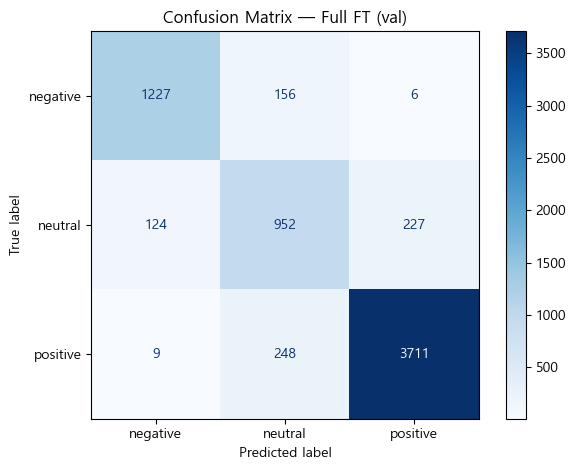


✅ Full FT 학습 완료
   학습 파라미터: 109,083,651
   모델 크기    : 417.8 MB
   학습 시간    : 871.5초
   val Accuracy : 0.8844
   val Macro F1 : 0.8489
✅ 실험 로그 저장: D:\code_it\mission\mission13\experiment_logs\final_experiment_log.csv


In [12]:
# 셀 8 | Full Fine-Tuning 학습 및 모델 저장
import gc
import shutil
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from datasets import Dataset
import evaluate as evaluate_lib
import csv, os, time
from pathlib import Path

MODEL_NAME   = "beomi/KcELECTRA-base"
MAX_LENGTH   = 128
NUM_LABELS   = 3

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH,
    )

accuracy_metric = evaluate_lib.load("accuracy")
f1_metric       = evaluate_lib.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds    = np.argmax(logits, axis=1)
    acc      = accuracy_metric.compute(predictions=preds, references=labels)["accuracy"]
    macro_f1 = f1_metric.compute(predictions=preds, references=labels, average="macro")["f1"]
    return {"accuracy": round(acc, 4), "macro_f1": round(macro_f1, 4)}

def build_hf_dataset(df):
    ds = Dataset.from_pandas(df[["text", "label"]])
    ds = ds.map(tokenize_fn, batched=True)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
    return ds

def get_dir_size_mb(path):
    total = sum(
        os.path.getsize(os.path.join(dp, f))
        for dp, _, files in os.walk(path)
        for f in files
    )
    return total / (1024 ** 2)

# 실험 로그 초기화 (재실행 시 중복 누적 방지)
LOG_FILE = Path(LOG_DIR) / "final_experiment_log.csv"
if LOG_FILE.exists():
    LOG_FILE.unlink()

LOG_COLUMNS = [
    "실험명", "방식", "epoch", "batch_size", "learning_rate",
    "max_length", "min_char_filter", "class_balance",
    "accuracy", "macro_f1", "학습시간(초)", "메모"
]

def save_experiment_log(log: dict):
    file_exists = LOG_FILE.exists()
    with open(LOG_FILE, "a", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=LOG_COLUMNS)
        if not file_exists:
            writer.writeheader()
        writer.writerow({col: log.get(col, "") for col in LOG_COLUMNS})
    print(f"✅ 실험 로그 저장: {LOG_FILE}")

# ── Dataset 변환 (셀 7에서 완료된 df_train_clean, df_val_clean 사용) ──
train_ds = build_hf_dataset(df_train_clean)
val_ds   = build_hf_dataset(df_val_clean)

# ── Full FT 학습 ──────────────────────────────────────────────────
model_full_ft = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS
)
FULL_FT_PARAM = sum(p.numel() for p in model_full_ft.parameters() if p.requires_grad)

args_full_ft = TrainingArguments(
    output_dir                  = "./results_final_full_ft",
    num_train_epochs            = 3,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 16,
    learning_rate               = 2e-5,
    warmup_ratio                = 0.1,
    weight_decay                = 0.01,
    lr_scheduler_type           = "cosine",
    eval_strategy               = "epoch",
    save_strategy               = "epoch",
    load_best_model_at_end      = True,
    metric_for_best_model       = "macro_f1",
    greater_is_better           = True,
    save_total_limit            = 1,
    report_to                   = "none",
    seed                        = SEED,
)

trainer_full_ft = Trainer(
    model           = model_full_ft,
    args            = args_full_ft,
    train_dataset   = train_ds,
    eval_dataset    = val_ds,
    compute_metrics = compute_metrics,
)

start = time.time()
trainer_full_ft.train()
FULL_FT_TRAIN_TIME = time.time() - start

# ── val 평가 ──────────────────────────────────────────────────────
predictions     = trainer_full_ft.predict(val_ds)
preds           = np.argmax(predictions.predictions, axis=1)
labels          = predictions.label_ids
FULL_FT_VAL_ACC = accuracy_score(labels, preds)
FULL_FT_VAL_F1  = f1_score(labels, preds, average="macro")

print("▶ Classification Report (val)")
print(classification_report(labels, preds, target_names=[LABEL_TO_NAME[i] for i in range(NUM_LABELS)]))

cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=[LABEL_TO_NAME[i] for i in range(NUM_LABELS)]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Full FT (val)")
plt.tight_layout()
plt.show()

# ── 모델 저장 (기존 폴더 초기화 후 저장) ─────────────────────────
SAVE_DIR_FULL_FT = os.path.join(LOG_DIR, "saved_models", "final_full_ft")
if os.path.exists(SAVE_DIR_FULL_FT):
    shutil.rmtree(SAVE_DIR_FULL_FT)  # 기존 파일 제거 → 모델 크기 계산 정확도 확보

trainer_full_ft.save_model(SAVE_DIR_FULL_FT)
tokenizer.save_pretrained(SAVE_DIR_FULL_FT)
FULL_FT_MODEL_SIZE = get_dir_size_mb(SAVE_DIR_FULL_FT)

print(f"\n✅ Full FT 학습 완료")
print(f"   학습 파라미터: {FULL_FT_PARAM:,}")
print(f"   모델 크기    : {FULL_FT_MODEL_SIZE:.1f} MB")
print(f"   학습 시간    : {FULL_FT_TRAIN_TIME:.1f}초")
print(f"   val Accuracy : {FULL_FT_VAL_ACC:.4f}")
print(f"   val Macro F1 : {FULL_FT_VAL_F1:.4f}")

save_experiment_log({
    "실험명"          : "final_full_ft",
    "방식"            : "Full Fine-Tuning",
    "epoch"           : 3,
    "batch_size"      : 16,
    "learning_rate"   : 2e-5,
    "max_length"      : MAX_LENGTH,
    "min_char_filter" : f"{MIN_CHAR_LEN}자 이상",
    "class_balance"   : "없음",
    "accuracy"        : round(FULL_FT_VAL_ACC, 4),
    "macro_f1"        : round(FULL_FT_VAL_F1, 4),
    "학습시간(초)"    : round(FULL_FT_TRAIN_TIME, 1),
    "메모"            : f"warmup=0.1, weight_decay=0.01, cosine | 크기: {FULL_FT_MODEL_SIZE:.1f}MB | 파라미터: {FULL_FT_PARAM:,}",
})

In [13]:
# ── GPU 메모리 정리 ───────────────────────────────────────────────
del trainer_full_ft
del model_full_ft
gc.collect()
torch.cuda.empty_cache()
print("GPU 메모리 정리 완료")

GPU 메모리 정리 완료


## 6. PEFT — LoRA (Parameter-Efficient Fine-Tuning)

### LoRA 개요

LoRA(Low-Rank Adaptation)는 모델 전체를 학습하는 대신,  
가중치 행렬에 **저랭크 행렬 쌍(A, B)을 삽입**하여 해당 부분만 학습하는 방식입니다.

### LoRA 설정

| 항목 | 값 | 설명 |
|---|---|---|
| r (rank) | 32 | 저랭크 행렬의 차원. 클수록 표현력 증가 |
| lora_alpha | 64 | 스케일링 계수 (alpha/r = 2.0 유지) |
| lora_dropout | 0.05 | 과적합 방지 |
| target_modules | query, key, value, output.dense | LoRA 적용 레이어 |
| modules_to_save | classifier | 감성 분류 head 저장 |
| learning rate | 1e-4 | Full FT 대비 높은 lr (학습 파라미터가 적어 더 큰 업데이트 필요) |
| epoch | 3 | |
| batch size | 16 | |

### 저장 방식 및 추론 시 유의사항

LoRA 모델은 전체 KcELECTRA 가중치를 저장하는 것이 아니라,  
학습된 **adapter와 classifier head만 저장**합니다.  
따라서 실제 추론 시에는 원본 `beomi/KcELECTRA-base` 모델과  
저장된 LoRA adapter를 **함께 로드**해야 합니다.

```python
from peft import PeftModel
base_model = AutoModelForSequenceClassification.from_pretrained("beomi/KcELECTRA-base", num_labels=3)
model = PeftModel.from_pretrained(base_model, "저장된_LoRA_경로")
```

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at beomi/KcELECTRA-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


학습 파라미터: 4,426,755 / 113,510,406 (3.90%)


  9%|▊         | 501/5829 [01:00<10:18,  8.62it/s]

{'loss': 0.6791, 'grad_norm': 2.555495262145996, 'learning_rate': 8.576329331046313e-05, 'epoch': 0.26}


 17%|█▋        | 1001/5829 [01:58<09:22,  8.59it/s]

...

{'eval_loss': 0.29553478956222534, 'eval_accuracy': 0.885, 'eval_macro_f1': 0.8458, 'eval_runtime': 20.4033, 'eval_samples_per_second': 326.418, 'eval_steps_per_second': 20.438, 'epoch': 3.0}


100%|██████████| 5829/5829 [12:46<00:00,  7.60it/s]


{'train_runtime': 766.5381, 'train_samples_per_second': 121.622, 'train_steps_per_second': 7.604, 'train_loss': 0.3313121641862247, 'epoch': 3.0}


100%|██████████| 417/417 [00:19<00:00, 21.79it/s]


▶ Classification Report (val)
              precision    recall  f1-score   support

    negative       0.92      0.86      0.89      1389
     neutral       0.71      0.71      0.71      1303
    positive       0.93      0.95      0.94      3968

    accuracy                           0.89      6660
   macro avg       0.85      0.84      0.85      6660
weighted avg       0.89      0.89      0.89      6660



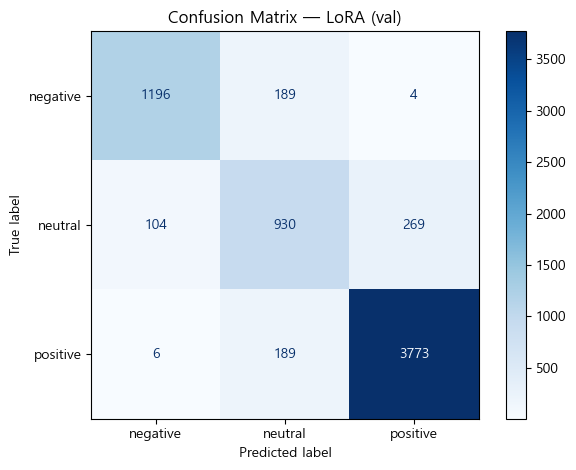


✅ LoRA 학습 완료
   학습 파라미터: 4,426,755 (3.90%)
   모델 크기    : 16.9 MB
   학습 시간    : 766.7초
   val Accuracy : 0.8857
   val Macro F1 : 0.8472
✅ 실험 로그 저장: D:\code_it\mission\mission13\experiment_logs\final_experiment_log.csv


In [14]:
# 셀 9 | PEFT - LoRA 학습 및 모델 저장
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    task_type       = TaskType.SEQ_CLS,
    r               = 32,
    lora_alpha      = 64,
    lora_dropout    = 0.05,
    target_modules  = ["query", "key", "value", "output.dense"],
    bias            = "none",
    modules_to_save = ["classifier"],  # classifier head도 함께 저장
)

base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS
)
model_lora = get_peft_model(base_model, lora_config)

LORA_TRAINABLE = sum(p.numel() for p in model_lora.parameters() if p.requires_grad)
LORA_TOTAL     = sum(p.numel() for p in model_lora.parameters())
print(f"학습 파라미터: {LORA_TRAINABLE:,} / {LORA_TOTAL:,} ({LORA_TRAINABLE/LORA_TOTAL*100:.2f}%)")

args_lora = TrainingArguments(
    output_dir                  = "./results_final_lora",
    num_train_epochs            = 3,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 16,
    learning_rate               = 1e-4,
    warmup_ratio                = 0.1,
    weight_decay                = 0.01,
    lr_scheduler_type           = "cosine",
    eval_strategy               = "epoch",
    save_strategy               = "epoch",
    load_best_model_at_end      = True,
    metric_for_best_model       = "macro_f1",
    greater_is_better           = True,
    save_total_limit            = 1,
    report_to                   = "none",
    seed                        = SEED,
)

trainer_lora = Trainer(
    model           = model_lora,
    args            = args_lora,
    train_dataset   = train_ds,
    eval_dataset    = val_ds,
    compute_metrics = compute_metrics,
)

start = time.time()
trainer_lora.train()
LORA_TRAIN_TIME = time.time() - start

# ── val 평가 ──────────────────────────────────────────────────────
predictions  = trainer_lora.predict(val_ds)
preds        = np.argmax(predictions.predictions, axis=1)
labels       = predictions.label_ids
LORA_VAL_ACC = accuracy_score(labels, preds)
LORA_VAL_F1  = f1_score(labels, preds, average="macro")

print("▶ Classification Report (val)")
print(classification_report(labels, preds, target_names=[LABEL_TO_NAME[i] for i in range(NUM_LABELS)]))

cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=[LABEL_TO_NAME[i] for i in range(NUM_LABELS)]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — LoRA (val)")
plt.tight_layout()
plt.show()

# ── 모델 저장 (기존 폴더 초기화 후 저장) ─────────────────────────
SAVE_DIR_LORA = os.path.join(LOG_DIR, "saved_models", "final_lora")
if os.path.exists(SAVE_DIR_LORA):
    shutil.rmtree(SAVE_DIR_LORA)  # 기존 파일 제거 → 모델 크기 계산 정확도 확보

model_lora.save_pretrained(SAVE_DIR_LORA)
LORA_MODEL_SIZE = get_dir_size_mb(SAVE_DIR_LORA)

print(f"\n✅ LoRA 학습 완료")
print(f"   학습 파라미터: {LORA_TRAINABLE:,} ({LORA_TRAINABLE/LORA_TOTAL*100:.2f}%)")
print(f"   모델 크기    : {LORA_MODEL_SIZE:.1f} MB")
print(f"   학습 시간    : {LORA_TRAIN_TIME:.1f}초")
print(f"   val Accuracy : {LORA_VAL_ACC:.4f}")
print(f"   val Macro F1 : {LORA_VAL_F1:.4f}")

save_experiment_log({
    "실험명"          : "final_lora",
    "방식"            : "PEFT-LoRA",
    "epoch"           : 3,
    "batch_size"      : 16,
    "learning_rate"   : 1e-4,
    "max_length"      : MAX_LENGTH,
    "min_char_filter" : f"{MIN_CHAR_LEN}자 이상",
    "class_balance"   : "없음",
    "accuracy"        : round(LORA_VAL_ACC, 4),
    "macro_f1"        : round(LORA_VAL_F1, 4),
    "학습시간(초)"    : round(LORA_TRAIN_TIME, 1),
    "메모"            : f"r=32, alpha=64, dropout=0.05, modules_to_save=['classifier'] | 크기: {LORA_MODEL_SIZE:.1f}MB | 학습파라미터: {LORA_TRAINABLE:,}",
})

In [15]:
# ── GPU 메모리 정리 ───────────────────────────────────────────────
del trainer_lora
del model_lora
del base_model
gc.collect()
torch.cuda.empty_cache()
print("GPU 메모리 정리 완료")

GPU 메모리 정리 완료


## 7. 최종 평가 (test set)

> ⚠️ **test set은 이 셀에서 단 1회만 사용합니다.**  
> 모든 하이퍼파라미터 튜닝과 모델 선택은 val set 기준으로 완료된 상태입니다.

test set에도 동일한 전처리(clean 함수 + 10자 이상 길이 필터)를 적용한 후 평가를 진행합니다.  
저장된 모델을 로드하여 평가함으로써 학습 과정과 독립적인 최종 성능을 측정합니다.

최종 비교에서는 Accuracy와 Macro F1뿐 아니라 학습 시간, 저장 용량, 학습 파라미터 수를  
함께 비교하여 **성능과 효율성을 동시에 분석**합니다.

test set 전처리 후: 6,659개 (원본: 6,660개)


100%|██████████| 417/417 [00:17<00:00, 23.96it/s]


▶ Full Fine-Tuning — test 평가 결과
              precision    recall  f1-score   support

    negative       0.90      0.87      0.89      1389
     neutral       0.70      0.72      0.71      1302
    positive       0.94      0.94      0.94      3968

    accuracy                           0.88      6659
   macro avg       0.85      0.84      0.85      6659
weighted avg       0.88      0.88      0.88      6659



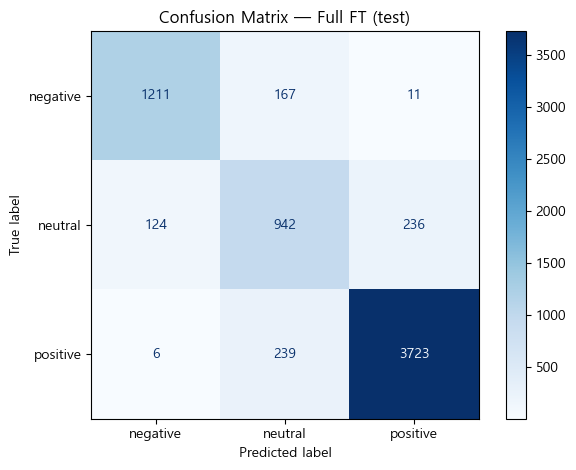

  [val]   Accuracy: 0.8844 | Macro F1: 0.8489
  [test]  Accuracy: 0.8824 | Macro F1: 0.8454


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at beomi/KcELECTRA-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
100%|██████████| 417/417 [00:19<00:00, 21.15it/s]



▶ PEFT (LoRA) — test 평가 결과
              precision    recall  f1-score   support

    negative       0.91      0.83      0.87      1389
     neutral       0.67      0.69      0.68      1302
    positive       0.92      0.94      0.93      3968

    accuracy                           0.87      6659
   macro avg       0.84      0.82      0.83      6659
weighted avg       0.87      0.87      0.87      6659



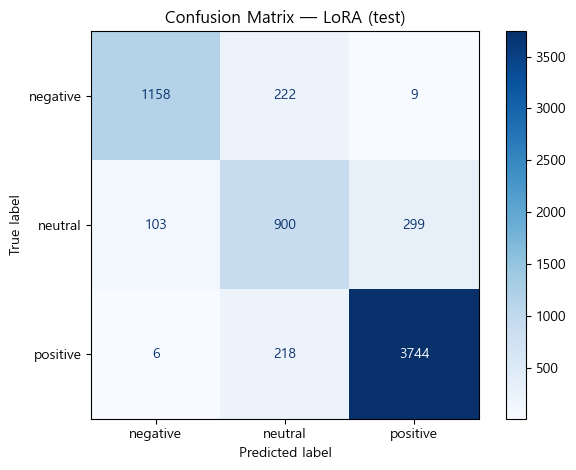

  [val]   Accuracy: 0.8857 | Macro F1: 0.8472
  [test]  Accuracy: 0.8713 | Macro F1: 0.8290
✅ 실험 로그 저장: D:\code_it\mission\mission13\experiment_logs\final_experiment_log.csv
✅ 실험 로그 저장: D:\code_it\mission\mission13\experiment_logs\final_experiment_log.csv

▶ Full FT vs LoRA 최종 비교


,방식,Val Accuracy,Val Macro F1,Test Accuracy,Test Macro F1,학습 시간(초),모델 크기(MB),학습 파라미터
0,Full Fine-Tuning,0.8844,0.8489,0.8824,0.8454,871.5,417.8,109083651
1,PEFT-LoRA,0.8857,0.8472,0.8713,0.8290,766.7,16.9,4426755



✅ 최종 평가 완료


In [16]:
# 셀 10 | 최종 평가 (test set) — ⚠️ 1회만 실행
from peft import PeftModel

# ── test set 전처리 (train/val과 동일하게 적용) ───────────────────
df_test_clean = FINAL_TEST_SET.copy()
df_test_clean["text"] = df_test_clean["text"].apply(clean)
df_test_clean = df_test_clean[
    (df_test_clean["text"].str.strip() != "") &
    (df_test_clean["text"].str.len() >= MIN_CHAR_LEN)
].reset_index(drop=True)
print(f"test set 전처리 후: {len(df_test_clean):,}개 (원본: {len(FINAL_TEST_SET):,}개)")

test_ds = build_hf_dataset(df_test_clean)

# ── Full FT test 평가 ─────────────────────────────────────────────
model_full_ft_eval = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR_FULL_FT)
trainer_full_ft_eval = Trainer(
    model=model_full_ft_eval,
    args=TrainingArguments(
        output_dir="./eval_tmp",
        per_device_eval_batch_size=16,
        report_to="none",
    ),
    compute_metrics=compute_metrics,
)

pred_full    = trainer_full_ft_eval.predict(test_ds)
preds_full   = np.argmax(pred_full.predictions, axis=1)
labels_test  = pred_full.label_ids

FULL_FT_TEST_ACC = accuracy_score(labels_test, preds_full)
FULL_FT_TEST_F1  = f1_score(labels_test, preds_full, average="macro")

print("\n" + "=" * 55)
print("▶ Full Fine-Tuning — test 평가 결과")
print("=" * 55)
print(classification_report(
    labels_test, preds_full,
    target_names=[LABEL_TO_NAME[i] for i in range(NUM_LABELS)]
))
cm = confusion_matrix(labels_test, preds_full)
ConfusionMatrixDisplay(cm, display_labels=[LABEL_TO_NAME[i] for i in range(NUM_LABELS)]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Full FT (test)")
plt.tight_layout()
plt.show()
print(f"  [val]   Accuracy: {FULL_FT_VAL_ACC:.4f} | Macro F1: {FULL_FT_VAL_F1:.4f}")
print(f"  [test]  Accuracy: {FULL_FT_TEST_ACC:.4f} | Macro F1: {FULL_FT_TEST_F1:.4f}")

# ── LoRA test 평가 ────────────────────────────────────────────────
base_model_eval = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS
)
model_lora_eval = PeftModel.from_pretrained(base_model_eval, SAVE_DIR_LORA)
trainer_lora_eval = Trainer(
    model=model_lora_eval,
    args=TrainingArguments(
        output_dir="./eval_tmp",
        per_device_eval_batch_size=16,
        report_to="none",
    ),
    compute_metrics=compute_metrics,
)

pred_lora  = trainer_lora_eval.predict(test_ds)
preds_lora = np.argmax(pred_lora.predictions, axis=1)

LORA_TEST_ACC = accuracy_score(labels_test, preds_lora)
LORA_TEST_F1  = f1_score(labels_test, preds_lora, average="macro")

print("\n" + "=" * 55)
print("▶ PEFT (LoRA) — test 평가 결과")
print("=" * 55)
print(classification_report(
    labels_test, preds_lora,
    target_names=[LABEL_TO_NAME[i] for i in range(NUM_LABELS)]
))
cm = confusion_matrix(labels_test, preds_lora)
ConfusionMatrixDisplay(cm, display_labels=[LABEL_TO_NAME[i] for i in range(NUM_LABELS)]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — LoRA (test)")
plt.tight_layout()
plt.show()
print(f"  [val]   Accuracy: {LORA_VAL_ACC:.4f} | Macro F1: {LORA_VAL_F1:.4f}")
print(f"  [test]  Accuracy: {LORA_TEST_ACC:.4f} | Macro F1: {LORA_TEST_F1:.4f}")

# ── 로그 저장 ─────────────────────────────────────────────────────
for exp_name, test_acc, test_f1 in [
    ("final_test_full_ft", FULL_FT_TEST_ACC, FULL_FT_TEST_F1),
    ("final_test_lora",    LORA_TEST_ACC,    LORA_TEST_F1),
]:
    save_experiment_log({
        "실험명"          : exp_name,
        "방식"            : "Full FT" if "full" in exp_name else "PEFT-LoRA",
        "epoch"           : "-",
        "batch_size"      : "-",
        "learning_rate"   : "-",
        "max_length"      : MAX_LENGTH,
        "min_char_filter" : f"{MIN_CHAR_LEN}자 이상",
        "class_balance"   : "없음",
        "accuracy"        : round(test_acc, 4),
        "macro_f1"        : round(test_f1, 4),
        "학습시간(초)"    : "-",
        "메모"            : "최종 test set 평가",
    })

# ── 최종 비교표 ───────────────────────────────────────────────────
print("\n" + "=" * 55)
print("▶ Full FT vs LoRA 최종 비교")
print("=" * 55)

final_summary = pd.DataFrame([
    {
        "방식"          : "Full Fine-Tuning",
        "Val Accuracy"  : round(FULL_FT_VAL_ACC, 4),
        "Val Macro F1"  : round(FULL_FT_VAL_F1, 4),
        "Test Accuracy" : round(FULL_FT_TEST_ACC, 4),
        "Test Macro F1" : round(FULL_FT_TEST_F1, 4),
        "학습 시간(초)" : round(FULL_FT_TRAIN_TIME, 1),
        "모델 크기(MB)" : round(FULL_FT_MODEL_SIZE, 1),
        "학습 파라미터" : FULL_FT_PARAM,
    },
    {
        "방식"          : "PEFT-LoRA",
        "Val Accuracy"  : round(LORA_VAL_ACC, 4),
        "Val Macro F1"  : round(LORA_VAL_F1, 4),
        "Test Accuracy" : round(LORA_TEST_ACC, 4),
        "Test Macro F1" : round(LORA_TEST_F1, 4),
        "학습 시간(초)" : round(LORA_TRAIN_TIME, 1),
        "모델 크기(MB)" : round(LORA_MODEL_SIZE, 1),
        "학습 파라미터" : LORA_TRAINABLE,
    },
])
display(final_summary)

print("\n✅ 최종 평가 완료")

## 8. 최종 실험 결과 분석 ##

---

### 8.1 하이퍼파라미터 튜닝 결과 ###

#### Full Fine-Tuning 튜닝 실험 ####

| 실험 | epoch | batch | lr | warmup | scheduler | val Macro F1 | 학습시간(초) |
|---|---:|---:|---:|---:|---|---:|---:|
| base_01 (기준) | 3 | 16 | 2e-5 | - | linear | 0.8517 | 763 |
| full_ft_v1 | 3 | 16 | 2e-5 | 0.1 | linear | 0.8467 | 811 |
| full_ft_v2 ✅ | 3 | 16 | 2e-5 | 0.1 | cosine | **0.8480** | 1,283 |
| full_ft_v3 | 5 | 32 | 2e-5 | 0.1 | cosine | 0.8469 | 23,651 |

**full_ft_v2 선정 근거**

- cosine scheduler와 warmup 조합을 적용했을 때 validation에서 test로 넘어가는 성능 하락폭이 작게 나타났다.
- full_ft_v3는 epoch를 5로 늘렸지만 성능 개선은 제한적이었고, 학습 시간이 약 6.5시간으로 과도하게 증가하였다.
- 따라서 성능과 학습 효율을 함께 고려하여 full_ft_v2 설정을 최종 Full Fine-Tuning 방식으로 선택하였다.

---

#### PEFT-LoRA 튜닝 실험

| 실험 | r | alpha | target_modules | lr | val Macro F1 | 모델크기(MB) |
|---|---:|---:|---|---:|---:|---:|
| base_01 LoRA (기준) | 16 | 32 | q/k/v | 2e-5 | 0.7919 | 5.7 |
| lora_v1 | 32 | 64 | q/k/v | 1e-4 | 0.8373 | 9.0 |
| lora_v2 ✅ | 32 | 64 | q/k/v/output.dense | 1e-4 | **0.8451** | 16.9 |
| lora_v3 | 32 | 64 | q/k/v/output.dense | 1e-4 | 중단 | - |

**lora_v2 선정 근거**

- r을 32로 증가시켜 LoRA adapter의 표현력을 높였다.
- 학습 파라미터 수가 적은 LoRA 특성을 고려하여 learning rate를 1e-4로 높게 설정하였다.
- `query`, `key`, `value`뿐 아니라 `output.dense` 계열까지 학습 범위를 확장하여 출력 표현까지 조정할 수 있도록 하였다.
- base_01 LoRA 대비 val Macro F1이 0.7919에서 0.8451로 약 **+0.0532 향상**되었다.
- lora_v3는 학습 시간이 과도하게 길어졌고, 중간 성능이 lora_v2보다 우수하지 않아 최종 후보에서 제외하였다.

---

#### PEFT 추가 실험 — AdaLoRA / Expanded IA³

미션 가이드라인에서 제시된 다양한 PEFT 방식 비교를 보강하기 위해, LoRA 외에 **AdaLoRA**와 **Expanded IA³** 실험을 추가로 진행하였다.  
본 실험에서 Expanded IA³는 별도의 공식 구현체가 아니라, `IA3Config`의 적용 레이어 범위를 넓힌 방식으로 정의하였다.

**AdaLoRA 성능 저하 원인 및 수정**

- base_01에서는 AdaLoRA의 rank 조정 스케줄 설정이 충분하지 않아 Macro F1이 0.2489로 매우 낮게 나타났다.
- base_03에서는 `total_step`, `tinit`, `tfinal`을 명확히 지정하여 재실험하였다.
- 그 결과 val Macro F1이 0.8188, test Macro F1이 0.8080으로 회복되어 정상적인 학습이 이루어졌음을 확인하였다.

**Expanded IA³ 적용 이유 및 수정**

- 기존 IA³ 설정에서는 KcELECTRA 구조에 비해 조정 가능한 범위가 제한적이라고 판단하였다.
- 이에 `intermediate.dense`와 `output.dense` 계열까지 적용 범위를 확장하여, feedforward 및 출력 표현을 함께 조정할 수 있도록 구성하였다.
- 그 결과 base_01 IA³ 대비 성능은 크게 개선되었지만, LoRA보다는 낮은 성능을 보였다.

| 실험 | 방식 | val Macro F1 | test Macro F1 | 비고 |
|---|---|---:|---:|---|
| base_01 AdaLoRA | AdaLoRA | 0.2489 | - | rank 조정 스케줄 설정 부족으로 성능 저하 |
| base_03 AdaLoRA ✅ | AdaLoRA | 0.8188 | 0.8080 | 스케줄 수정 후 정상 학습 |
| base_01 IA³ | IA³ | 0.5176 | - | 적용 범위가 제한되어 성능 저하 |
| base_03 Expanded IA³ ✅ | Expanded IA³ | 0.8165 | 0.8061 | 적용 범위 확장 후 성능 개선 |

---

### 8.2 최종 모델 설정 요약

#### Full Fine-Tuning 최종 설정

| 항목 | 값 |
|---|---|
| 모델 | beomi/KcELECTRA-base |
| epoch | 3 |
| batch size | 16 |
| learning rate | 2e-5 |
| warmup ratio | 0.1 |
| weight decay | 0.01 |
| lr scheduler | cosine |
| 전처리 | KcELECTRA 공식 clean 함수 + 10자 이상 필터 |

---

#### PEFT-LoRA 최종 설정

| 항목 | 값 |
|---|---|
| 모델 | beomi/KcELECTRA-base |
| r (rank) | 32 |
| lora_alpha | 64 |
| lora_dropout | 0.05 |
| target_modules | query, key, value, output.dense |
| modules_to_save | classifier |
| learning rate | 1e-4 |
| epoch | 3 |
| batch size | 16 |
| 전처리 | KcELECTRA 공식 clean 함수 + 10자 이상 필터 |

---

#### PEFT-AdaLoRA 설정

| 항목 | 값 |
|---|---|
| 모델 | beomi/KcELECTRA-base |
| init_r | 32 |
| target_r | 16 |
| lora_alpha | 64 |
| lora_dropout | 0.05 |
| target_modules | query, key, value, output.dense |
| modules_to_save | classifier |
| total_step | ceil(train 샘플 수 / batch_size) × epoch |
| tinit | total_step × 0.1 |
| tfinal | total_step × 0.9 |
| learning rate | 1e-4 |
| epoch | 3 |
| batch size | 16 |
| 전처리 | KcELECTRA 공식 clean 함수 + 10자 이상 필터 |

---

#### PEFT-Expanded IA³ 설정

| 항목 | 값 |
|---|---|
| 모델 | beomi/KcELECTRA-base |
| target_modules | key, value, output.dense, intermediate.dense |
| feedforward_modules | output.dense, intermediate.dense |
| modules_to_save | classifier |
| learning rate | 1e-3 |
| epoch | 3 |
| batch size | 16 |
| 전처리 | KcELECTRA 공식 clean 함수 + 10자 이상 필터 |

---

### 8.3 최종 성능 비교

#### 전체 방식 val / test 성능 비교

| 방식 | val Accuracy | val Macro F1 | test Accuracy | test Macro F1 | F1 변화 |
|---|---:|---:|---:|---:|---:|
| Full Fine-Tuning | 0.8844 | **0.8489** | **0.8824** | **0.8454** | -0.0035 |
| PEFT-LoRA | **0.8857** | 0.8472 | 0.8713 | 0.8290 | -0.0182 |
| PEFT-AdaLoRA | 0.8671 | 0.8188 | 0.8578 | 0.8080 | -0.0108 |
| PEFT-Expanded IA³ | 0.8662 | 0.8165 | 0.8567 | 0.8061 | -0.0104 |

- Full Fine-Tuning은 val → test F1 하락폭이 -0.0035로 전체 실험 중 가장 안정적인 일반화 성능을 보였다.
- PEFT-LoRA는 val Accuracy 기준으로는 가장 높았지만, test에서는 Full Fine-Tuning보다 낮게 나타났다.
- AdaLoRA와 Expanded IA³는 base_01 대비 설정을 보완한 뒤 정상 학습에 성공하였으며, 두 방식 모두 test Macro F1 0.80 이상을 달성하였다.
- PEFT 방식 중에서는 LoRA가 가장 높은 test Macro F1을 기록하였다.

---

#### 클래스별 성능 분석 (test set 기준)

| 클래스 | Full FT | LoRA | AdaLoRA | Expanded IA³ | 비고 |
|---|---:|---:|---:|---:|---|
| negative | 0.89 | 0.87 | 0.86 | 0.86 | 전체 방식 안정적 |
| **neutral** | **0.71** | **0.68** | **0.63** | **0.63** | 전체 실험 공통 병목 |
| positive | 0.94 | 0.93 | 0.93 | 0.93 | 전체 방식 높은 성능 |

**neutral 클래스 병목 원인 분석**

- neutral 리뷰는 긍정과 부정 표현이 함께 포함된 경우가 많아 분류 난도가 높다.
  - 예: "색감 좋고 탄력 좋은데 좀 두꺼워요" → 긍정 표현이 강해 positive로 오분류될 수 있음
  - 예: "가벼워서 신기 좋아요. 마감 처리가 조금 아쉽네요" → 긍정과 부정 감성이 혼재됨
- 클래스 분포에서 positive가 약 59.6%로 가장 많아 모델이 positive 방향으로 편향될 가능성이 있다.
- Full FT에 비해 PEFT 방식들은 neutral 클래스에서 상대적으로 낮은 F1을 보였으며, 이는 제한된 학습 파라미터만으로 혼합 감성 표현을 충분히 조정하기 어려웠기 때문으로 해석된다.

---

### 8.4 효율성 비교

| 방식 | test Macro F1 | 학습 시간(초) | 모델 크기(MB) | 학습 파라미터 | 파라미터 비율 | F1/파라미터 1M |
|---|---:|---:|---:|---:|---:|---:|
| Full Fine-Tuning | **0.8454** | 871.5 | 417.8 | 109,083,651 | 100% | 0.0078 |
| PEFT-LoRA | 0.8290 | 766.7 | 16.9 | 4,426,755 | 4.06% | 0.1873 |
| PEFT-AdaLoRA | 0.8080 | 1,019.5 | 16.9 | 4,428,675 | 4.06% | 0.1824 |
| PEFT-Expanded IA³ | 0.8061 | **631.4** | **2.4** | **629,763** | **0.58%** | **1.2800** |

**트레이드오프 분석**

- **성능**: Full Fine-Tuning이 test Macro F1 기준으로 가장 높았다.
- **PEFT 내 성능**: PEFT 방식 중에서는 LoRA가 가장 높은 test Macro F1을 보였다.
- **학습 시간**: Expanded IA³가 631.4초로 가장 짧았으며, AdaLoRA는 rank 조정 오버헤드로 인해 1,019.5초로 가장 길었다.
- **모델 크기**: Expanded IA³ adapter는 2.4MB로 가장 경량이며, Full FT(417.8MB) 대비 약 174배 작았다.
- **파라미터 효율**: Expanded IA³는 전체 파라미터의 0.58%만 학습하면서 F1 0.8061을 달성하여 파라미터 효율이 가장 높았다.
- **성능-효율 균형**: LoRA는 Expanded IA³보다 모델 크기는 크지만, test Macro F1이 더 높아 성능과 효율의 균형이 가장 좋았다.
- **추론 시 주의점**: PEFT 방식은 모두 adapter만 저장하므로, 실제 추론 시 원본 KcELECTRA-base 모델과 adapter를 함께 로드해야 한다.

---

### 8.5 결론

#### 방식별 권장 사용 시나리오

| 시나리오 | 권장 방식 | 근거 |
|---|---|---|
| 최고 성능이 필요한 경우 | Full Fine-Tuning | test Macro F1 0.8454로 최종 성능이 가장 높음 |
| PEFT 중 성능과 크기의 균형이 필요한 경우 | PEFT-LoRA | test Macro F1 0.8290, 모델 크기 16.9MB로 균형적 |
| 저장 용량이 가장 제한적인 경우 | PEFT-Expanded IA³ | adapter 크기 2.4MB로 전체 방식 중 가장 경량 |
| 여러 도메인에 빠르게 적용할 경우 | PEFT-LoRA | 베이스 모델 공유 후 도메인별 adapter만 교체 가능하며, 성능과 효율의 균형이 좋음 |

---

#### 한계점 및 향후 개선 방향

**1. neutral 클래스 성능 개선 필요**

- 전체 방식에서 neutral F1이 0.63~0.71로 가장 낮았으며, Full FT에 비해 PEFT 방식들은 neutral 클래스에서 상대적으로 낮은 성능을 보였다.
- neutral 리뷰는 긍정과 부정 표현이 혼재된 경우가 많아 단순한 3-class 분류에서 병목으로 작용하였다.
- 향후 neutral 샘플을 추가 수집하거나, Focal Loss 적용으로 어려운 샘플에 더 높은 가중치를 주는 방식을 시도할 수 있다.

**2. 실험 도메인 확장 필요**

- 이번 실험은 쇼핑몰 리뷰 중 패션 도메인 데이터만 사용하였다.
- 향후 화장품, 가전, IT기기, 생활 도메인까지 확장하면 도메인 일반화 성능을 더 정확히 확인할 수 있다.

**3. PEFT 추가 개선 가능성**

- AdaLoRA는 스케줄 설정을 보완한 뒤 정상 학습에 성공하였으나, LoRA 대비 성능이 낮고 학습 시간이 더 길었다. 향후 `init_r`, `target_r`, 스케줄 파라미터(`tinit`, `tfinal`) 조정으로 추가 개선이 가능하다.
- Expanded IA³는 파라미터 효율이 가장 높았으나 neutral 성능이 낮았다. `target_modules` 범위와 learning rate를 더 세밀하게 조정하면 성능 개선 여지가 있다.
- LoRA는 PEFT 방식 중 가장 안정적이었으므로, 향후에는 LoRA를 기준으로 `r`, `target_modules`, `lora_dropout`, scheduler를 추가 튜닝하는 방향이 적절하다.

---

### 8.6 최종 요약

본 실험에서는 쇼핑몰 패션 리뷰 데이터를 대상으로 KcELECTRA-base 모델을 활용하여 Full Fine-Tuning, LoRA, AdaLoRA, Expanded IA³ 네 가지 방식을 비교하였다.

최종 test set 기준으로 Full Fine-Tuning이 Macro F1 0.8454로 가장 높은 성능을 기록하였으며, val → test 하락폭도 -0.0035로 가장 안정적이었다. PEFT 방식 중에서는 LoRA가 test Macro F1 0.8290으로 가장 높은 성능과 균형 잡힌 효율을 보였고, Expanded IA³는 모델 크기 2.4MB, 학습 파라미터 비율 0.58%로 가장 높은 경량화 효과를 보였다.

따라서 성능을 최우선으로 하는 경우에는 Full Fine-Tuning이 가장 적합하다. PEFT 방식 중에서는 성능과 저장 효율의 균형을 고려할 때 LoRA가 가장 적절하며, 저장 용량을 극단적으로 줄이는 것이 중요한 경우에는 Expanded IA³를 선택할 수 있다.